In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [24]:
class Cleaning:
    def __init__(self, df: pd.DataFrame, primary_key: str):
        self.df = df
        self.primary_key = primary_key
        self.print_all_info()
        self.missing_values()
        self.drop_doublons()
        self.outlayers()
       


    def get_df(self):
        return self.df

    def print_all_info(self):
        print("===== DESCRIPTION =====")
        print(self.df.describe().to_string())

        print("===== SHAPE =====")
        print(self.df.shape)
        
        print("===== HEAD =====")
        print(self.df.head().to_string())

        print("===== COLONNES =====")
        print(list(self.df.columns))

        print("===== INFO =====")
        self.df.info()

# etape 3 : identifier les problèmes les valeurs manquantes
    def missing_values(self):
        unkown_values = self.df.isna().sum()
        print("Nombre de valeurs manquantes :",unkown_values)

# etape 3 : identifier les problèmes les doublons
    def drop_doublons(self):
        print("===== DOUBLONS =====")
        print(type(self.df[self.primary_key][0]))
        doublons = self.df[self.primary_key].duplicated().sum()
        print(f"Nombre de doublons : {doublons}")
        if doublons >= 1:
            self.df = self.df.drop_duplicates(subset=[self.primary_key])
        else:
            print("no doublons")
    

#MAJ quantiles 
    def maj_quantiles(self, col: str):
        self.Q1 = self.df[col].quantile(0.25)
        self.Q3 = self.df[col].quantile(0.75)
        self.IQR = self.Q3 - self.Q1

# etape 4 : valeurs abérrantes 
    def outlayers(self):
        for col in self.df.select_dtypes(include=['float64', 'int64']).columns:
            if col == self.primary_key:
                continue
            else:
                self.maj_quantiles(col)
                lower_bound = self.Q1 - 1.5 * self.IQR
                upper_bound = self.Q3 + 1.5 * self.IQR
                outliers = self.df[(self.df[col] < lower_bound) | (self.df[col] > upper_bound)]
                print(f"Nombre de valeurs aberrantes dans la colonne {col} : {len(outliers)}")

#etape 4 : valeurs aberrantes et boxplot sur une colonne 
    def outlayers_col(self, col: str):

        # Boxplot
        plt.figure(figsize=(8, 4))
        plt.boxplot(self.df[col].dropna())
        plt.title(f"Boxplot de {col}")
        plt.show()

        # Calcul IQR
        self.maj_quantiles(col)

        borne_inf = self.Q1 - 1.5 * self.IQR
        borne_sup = self.Q3 + 1.5 * self.IQR

        outliers = self.df[
            (self.df[col] < borne_inf) |
            (self.df[col] > borne_sup)
        ]

        return outliers

    #supprimer les colonnes inutiles
    def drop_col(self, cols: list):
        for col in cols:
            if col in self.df.columns:
                self.df = self.df.drop(columns=[col])
                print(f"Colonne '{col}' supprimée.")
            else:
                print(f"Colonne '{col}' non trouvée dans le DataFrame.")
        return self.df

In [25]:
import sys
from pathlib import Path

# Ajouter le dossier racine du projet au chemin de recherche Python
racine_projet = Path.cwd().parent
sys.path.insert(0, str(racine_projet))

from api.api_client import fetch_dataset

df_meteo = fetch_dataset("meteo")

===== DESCRIPTION =====
       identifiant_station    latitude   longitude  temperature_celsius  point_rosee_celsius  humidite_relative_pct  direction_vent_deg  vitesse_vent_ms  visibilite_m  pression_station_pa  pression_mer_pa
count         6.590000e+02  659.000000  659.000000           659.000000           220.000000             220.000000          329.000000       329.000000    110.000000           110.000000       110.000000
mean          7.511118e+07   48.847344    2.315754            11.882853             8.502273              79.172727          224.924012         6.792705  18120.454545         98946.363636     99869.727273
std           3.763892e+03    0.021481    0.040871             2.026952             1.673632               8.311140           46.500167         4.523395   3867.798223           982.546520       995.880929
min           7.510600e+07   48.821667    2.233667             7.200000             6.500000              59.000000            0.000000         0.000000   3

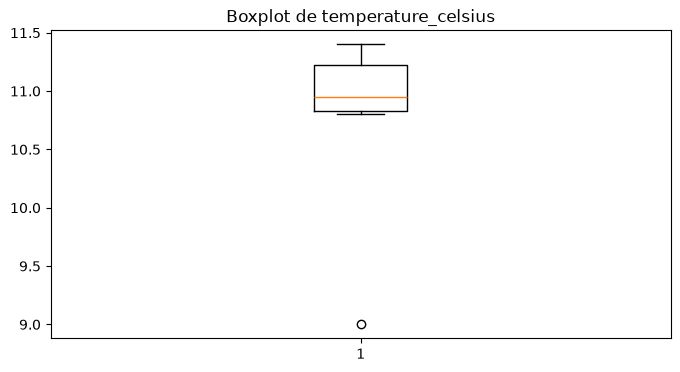

In [26]:
clean_df_meteo = Cleaning(df_meteo,	"identifiant_station")
clean_df_meteo.outlayers_col('temperature_celsius')
df_meteo = clean_df_meteo.get_df()